# 02: k-means

**The algorithm (Lloyd's).** Start with k centers. Repeat: assign every row to its nearest center, then move each center to the mean of its rows. Stop when no row changes cluster.

**Where the time goes.** Every iteration has two passes over the data. The *assign* step is a matrix multiply (rows × centers) plus an argmin. The *update* step sums rows per cluster, which is memory-bound. The Rust engine fuses both into one pass: it scores a block of rows, assigns them, and adds them to the running sums while they're still in cache.

**Fairness.** Every engine starts from the *same* k-means++ centers and runs the same number of iterations (`max_iter`), so the only difference is speed. Because iteration counts can differ by a hair (ties), the fair number is **time per iteration**.

In [1]:
import sys
sys.path.insert(0, ".")  # so bench_utils (next to this notebook) imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ml_in_rust as mr
from bench_utils import (machine_info, timeit, load_covtype, add_speedup,
                         save_results, line_chart, fmt_ms, only_available)

pd.set_option("display.float_format", "{:,.4f}".format)
%matplotlib inline
pd.Series(machine_info())

machine                                    macos-arm64-apple-m4
cpu                                                    Apple M4
cores                              4 performance + 6 efficiency
ram_gb                                                       24
os                          macOS-26.6.1-arm64-arm-64bit-Mach-O
python                                                   3.13.5
numpy                                  2.5.4 (BLAS: accelerate)
sklearn                                                   1.9.1
rust-blas matrix library                       Apple Accelerate
mlx                                     0.32.4 (Device(gpu, 0))
dtype: object

In [2]:
import os
QUICK = os.environ.get("QUICK") == "1"  # QUICK=1 ./run_all.sh for a fast smoke run
MAX_ITER = 30

from sklearn.cluster import KMeans as SkKMeans, kmeans_plusplus
from sklearn.datasets import make_blobs

def race(X, k, label, repeats=2):
    init, _ = kmeans_plusplus(X, k, random_state=0)
    init = init.astype(np.float32)
    models = only_available({
        "sklearn": lambda: SkKMeans(k, init=init, n_init=1, max_iter=MAX_ITER, tol=0, algorithm="lloyd"),
        "numpy": lambda: mr.KMeans(k, init=init, max_iter=MAX_ITER, backend="numpy"),
        "rust": lambda: mr.KMeans(k, init=init, max_iter=MAX_ITER, backend="rust"),
        "mlx": lambda: mr.KMeans(k, init=init, max_iter=MAX_ITER, backend="mlx"),
    })
    out, ref = [], None
    for name, make in models.items():
        fitted = {}
        def run():
            fitted["m"] = make().fit(X)
        t = timeit(run, repeats=repeats)
        m = fitted["m"]
        if name == "sklearn":
            ref = m
        out.append({**label, "engine": name, "fit s": t, "iterations": m.n_iter_,
                    "s per iteration": t / m.n_iter_, "inertia vs sklearn": m.inertia_ / ref.inertia_ - 1,
                    "labels agree": np.mean(m.labels_ == ref.labels_)})
    return out

## Race 1: real data (Covertype, 579k rows × 54 features, k = 16)

In [3]:
X, _ = load_covtype()
if QUICK:
    X = X[:50_000]
real = add_speedup(pd.DataFrame(race(X, 16, {"dataset": "covertype"})), "s per iteration", ["dataset"])
real

,dataset,engine,fit s,iterations,s per iteration,inertia vs sklearn,labels agree,vs sklearn
0,covertype,sklearn,0.1592,22,0.0072,0.0000,1.0000,1.0000
1,covertype,numpy,1.8764,22,0.0853,-0.0000,1.0000,0.0849
2,covertype,rust,0.0858,22,0.0039,-0.0000,1.0000,1.8566
3,covertype,mlx,0.3058,22,0.0139,-0.0000,1.0000,0.5208


## Race 2: more rows (synthetic blobs, 32 features, k = 32)

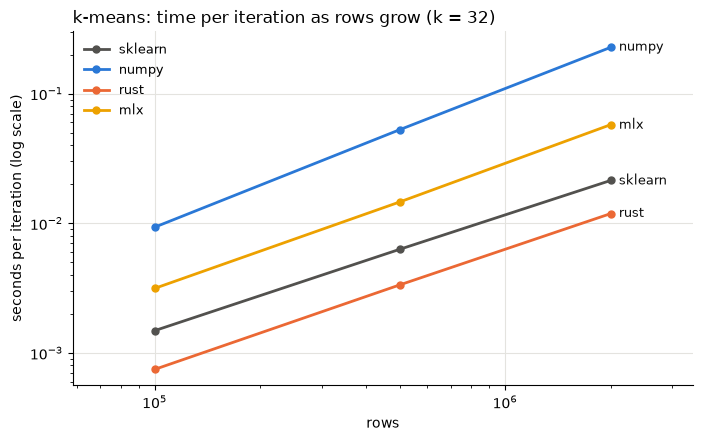

engine,mlx,numpy,rust,sklearn
rows,,,,
100000,0.4700,0.1600,1.9900,1.0000
500000,0.4300,0.1200,1.8800,1.0000
2000000,0.3700,0.0900,1.8000,1.0000


In [4]:
SIZES = [50_000, 200_000] if QUICK else [100_000, 500_000, 2_000_000]
rows = []
for n in SIZES:
    Xb, _ = make_blobs(n, n_features=32, centers=32, cluster_std=4.0, random_state=0)
    rows += race(Xb.astype(np.float32), 32, {"rows": n})
by_rows = add_speedup(pd.DataFrame(rows), "s per iteration", ["rows"])
line_chart(by_rows, "rows", "s per iteration", "k-means: time per iteration as rows grow (k = 32)",
           "rows", "seconds per iteration (log scale)")
plt.show()
by_rows.pivot(index="rows", columns="engine", values="vs sklearn").round(2)

## Race 3: more clusters (500k rows, 32 features)

More clusters means a bigger matrix multiply per iteration and a longer argmin per row.

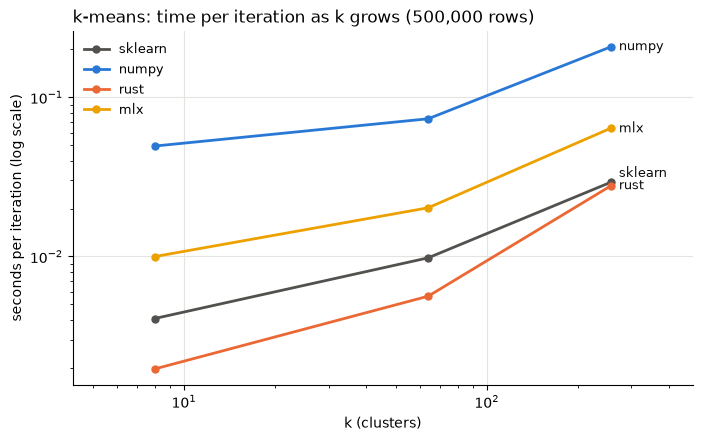

engine,mlx,numpy,rust,sklearn
k,,,,
8,0.4100,0.0800,2.0700,1.0000
64,0.4800,0.1300,1.7400,1.0000
256,0.4600,0.1400,1.0500,1.0000


In [5]:
n = 100_000 if QUICK else 500_000
Xb, _ = make_blobs(n, n_features=32, centers=64, cluster_std=4.0, random_state=1)
Xb = Xb.astype(np.float32)
rows = []
for k in [8, 64, 256]:
    rows += race(Xb, k, {"k": k}, repeats=1)
by_k = add_speedup(pd.DataFrame(rows), "s per iteration", ["k"])
line_chart(by_k, "k", "s per iteration", f"k-means: time per iteration as k grows ({n:,} rows)",
           "k (clusters)", "seconds per iteration (log scale)")
plt.show()
by_k.pivot(index="k", columns="engine", values="vs sklearn").round(2)

In [6]:
save_results("kmeans", by_rows, notes={"covertype": real.to_dict(orient="records"),
                                       "by_k": by_k.to_dict(orient="records")})
print("Quality check: inertia relative to scikit-learn (0 = identical) and label agreement")
pd.concat([real, by_rows, by_k])[["engine", "inertia vs sklearn", "labels agree"]].groupby("engine").agg(["min", "max"])

Quality check: inertia relative to scikit-learn (0 = identical) and label agreement


inertia vs sklearn        labels agree       
                       min    max          min    max
engine                                               
mlx                -0.0000 0.0000       0.9895 1.0000
numpy              -0.0000 0.0000       0.9890 1.0000
rust               -0.0000 0.0000       0.9879 1.0000
sklearn             0.0000 0.0000       1.0000 1.0000